# Interlocking Directorates na Elite Corporativa: Analisando Governança e Fluxo de Informação no Mercado de Capitais Brasileiro

**Autor:** João Victor do Nascimento Ribeiro de Andrade  
**Disciplina:** Algoritmos e Estruturas de Dados II (Teoria dos Grafos) - Projeto Final  
**Curso:** Engenharia de Computação  
**Ano Letivo:** 2026  

---

## Resumo Executivo
Este projeto investiga a topologia dos mandatos cruzados de administração (*interlocking directorates*) entre companhias de capital aberto registradas na Comissão de Valores Mobiliários (**CVM**). Ao modelar as afiliações corporativas como um grafo bipartido e obter sua projeção unipartite no espaço dos executivos, aplicamos os principais conceitos de teoria dos grafos abordados na disciplina — incluindo distribuições de graus, extração do componente gigante conexo, centralidades de intermediação e autovetor, e decomposição em $k$-core — para identificar as principais pontes de informação e o núcleo estrutural da governança corporativa no Brasil.


## 1. Problema e Questão de Pesquisa

### 1.1 Contexto e Definição do Problema
Na governança corporativa, ocorre um **interlocking directorate** (mandatos cruzados de administração) quando um indivíduo atua simultaneamente no conselho de administração ou na diretoria executiva de duas ou mais entidades corporativas distintas. Embora a literatura de governança corporativa frequentemente assuma que as empresas operam como agentes de mercado autônomos, a realidade empírica demonstra que as estruturas corporativas modernas são profundamente interconectadas.

Em economias emergentes e altamente concentradas como o Brasil, conglomerados econômicos, estruturas de *holding* e instituições financeiras frequentemente compartilham conselheiros de administração, membros do Conselho Fiscal e diretores estatutários. Esse fenômeno estrutural gera implicações cruciais:
1. **Concentração de Poder Corporativo:** A sobreposição de lideranças pode facilitar o alinhamento estratégico, ações coordenadas de mercado e cartéis tácitos.
2. **Fluxo Assimétrico de Informação:** Executivos com múltiplos assentos funcionam como canais rápidos de transmissão para tendências do setor, mudanças regulatórias, inteligência de fornecedores e oportunidades estratégicas.
3. **Dilemas de Governança e Teoria da Agência:** Mandatos simultâneos podem suscitar conflitos de interesse, lealdades divididas e redução na eficácia de monitoramento.

### 1.2 Pergunta Norteadora
Para examinar rigorosamente o panorama corporativo brasileiro, este estudo busca responder à seguinte questão central:

> **"Quais executivos atuam como as principais pontes de informação entre setores distintos, e qual é o grupo central (o 'núcleo') que comanda as maiores empresas do Brasil?"**

Por meio das metodologias formais de teoria dos grafos desenvolvidas ao longo da disciplina de *Algoritmos e Estruturas de Dados II*, respondemos sistematicamente a essa pergunta mapeando a arquitetura macroscópica da rede, identificando intermediadores estruturais e isolando o núcleo coeso mais profundo da elite corporativa.


## 2. Coleta e Higienização dos Dados

### 2.1 Visão Geral da Base de Dados
Os dados utilizados nesta investigação provêm do Portal de Dados Abertos oficial da CVM, especificamente do Formulário de Referência (**FRE**), Seção 12 (*Administradores e Membros do Conselho Fiscal*), referentes aos anos de exercício de 2025 e 2026. Os arquivos de origem estão estruturados nos diretórios locais:
- `fre_cia_aberta_2025/fre_cia_aberta_administrador_membro_conselho_fiscal.csv`
- `fre_cia_aberta_2026/fre_cia_aberta_administrador_membro_conselho_fiscal.csv`

### 2.2 Pipeline de Ingestão e Higienização
Para assegurar integridade dos dados:
1. Ambos os demonstrativos anuais são concatenados para abranger o conjunto integral dos órgãos de administração ativos.
2. Registros incompletos com valores nulos para razão social da companhia ou nome do executivo são descartados.
3. Espaços em branco são higienizados, strings de texto são padronizadas em caixa alta e nomeações duplicadas oriundas de múltiplas versões de entrega e datas de referência são consolidadas.
4. A saída é um DataFrame de afiliação estruturado contendo as duas colunas principais: `Company_Name` (Nome da Companhia) e `Person_Name` (Nome do Executivo).


In [7]:
# Ingestão e Higienização dos Dados
import os
import glob
import pandas as pd
import numpy as np

def resolve_csv_path(directory_name, file_prefix):
    """
    Localiza o caminho exato do arquivo CSV, verificando tanto o nome base quanto com sufixo de ano.
    """
    direct_path = os.path.join(directory_name, f"{file_prefix}.csv")
    if os.path.exists(direct_path):
        return direct_path
    pattern = os.path.join(directory_name, f"{file_prefix}*.csv")
    matches = glob.glob(pattern)
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Não foi possível localizar o arquivo para {file_prefix} em {directory_name}")

# Ingestão das bases da CVM de 2025 e 2026
file_prefix = "fre_cia_aberta_administrador_membro_conselho_fiscal"
path_2025 = resolve_csv_path("fre_cia_aberta_2025", file_prefix)
path_2026 = resolve_csv_path("fre_cia_aberta_2026", file_prefix)

print(f"Carregando base de 2025 de: {path_2025}")
print(f"Carregando base de 2026 de: {path_2026}")

df_2025 = pd.read_csv(path_2025, sep=";", encoding="latin1", low_memory=False)
df_2026 = pd.read_csv(path_2026, sep=";", encoding="latin1", low_memory=False)

# Concatenação das bases anuais
raw_df = pd.concat([df_2025, df_2026], ignore_index=True)
initial_row_count = len(raw_df)

# Limpeza dos dados: remoção de valores ausentes em identificadores obrigatórios
cleaned_df = raw_df.dropna(subset=["Nome_Companhia", "Nome"]).copy()

# Padronização de formato de texto
cleaned_df["Company_Name"] = cleaned_df["Nome_Companhia"].astype(str).str.strip().str.upper()
cleaned_df["Person_Name"] = cleaned_df["Nome"].astype(str).str.strip().str.upper()

# Seleção das duas colunas primárias e deduplicação de pares de afiliação ativos
board_df = cleaned_df[["Company_Name", "Person_Name"]].drop_duplicates().reset_index(drop=True)

# Resumo da base de dados
total_companies = board_df["Company_Name"].nunique()
total_persons = board_df["Person_Name"].nunique()
total_affiliations = len(board_df)

print("\n" + "="*50)
print("RELATÓRIO DE HIGIENIZAÇÃO DE DADOS")
print("="*50)
print(f"Total de registros brutos carregados: {initial_row_count:,}")
print(f"Vínculos de afiliação válidos:         {total_affiliations:,}")
print(f"Empresas de capital aberto distintas: {total_companies:,}")
print(f"Executivos e conselheiros distintos:  {total_persons:,}")
print("="*50)

# Exibição de amostra da base higienizada de afiliações
board_df.head(10)


Carregando base de 2025 de: fre_cia_aberta_2025\fre_cia_aberta_administrador_membro_conselho_fiscal_2025.csv
Carregando base de 2026 de: fre_cia_aberta_2026\fre_cia_aberta_administrador_membro_conselho_fiscal_2026.csv

RELATÓRIO DE HIGIENIZAÇÃO DE DADOS
Total de registros brutos carregados: 17,446
Vínculos de afiliação válidos:         8,994
Empresas de capital aberto distintas: 707
Executivos e conselheiros distintos:  6,912


,Company_Name,Person_Name
0,BCO BRASIL S.A.,TATIANA ROSITO
1,BCO BRASIL S.A.,ROSIANE BARBOSA LAVIOLA
2,BCO BRASIL S.A.,RAFAEL MACHADO GIOVANELLA
3,BCO BRASIL S.A.,JOÃO VAGNES DE MOURA SILVA
4,BCO BRASIL S.A.,FELIPE GUIMARÃES GEISSLER PRINCE
5,BCO BRASIL S.A.,TARCIANA PAULA GOMES MEDEIROS
6,BCO BRASIL S.A.,FERNANDO FLORÊNCIO CAMPOS
7,BCO BRASIL S.A.,ANDRIEI JOSÉ BEBER
8,BCO BRASIL S.A.,ANTONIO EMÍLIO BASTOS DE AGUIAR FREIRE
9,BCO BRASIL S.A.,ANA CRISTINA ROSA GARCIA


In [9]:
# ==============================================================================
# Sample Visualization: Bipartite Data Structure Preview (1 Company, 20 Executives)
# ==============================================================================
import networkx as nx
import plotly.graph_objects as go

# 1. Select a small sample: 1 company and exactly 20 of its executives
# We pick the company with the most executives to ensure we have enough data
top_company = board_df['Company_Name'].value_counts().index[0]
df_sample = board_df[board_df['Company_Name'] == top_company].head(20)

# 2. Build the sample bipartite graph
B_sample = nx.Graph()
exec_sample_nodes = df_sample['Person_Name'].unique()
comp_sample_nodes = [top_company]

B_sample.add_nodes_from(exec_sample_nodes, bipartite=0) # Executives
B_sample.add_nodes_from(comp_sample_nodes, bipartite=1) # Company
B_sample.add_edges_from(df_sample[['Person_Name', 'Company_Name']].values)

# 3. Create a strict Bipartite Layout (Company on left, Executives on right)
pos_sample = nx.bipartite_layout(B_sample, nodes=comp_sample_nodes)

# 4. Create edges traces
edge_x, edge_y = [], []
for u, v in B_sample.edges():
    x0, y0 = pos_sample[u]
    x1, y1 = pos_sample[v]
    edge_x.extend([x0, x1, None])
    edge_y.extend([y0, y1, None])

trace_edges = go.Scatter(
    x=edge_x, y=edge_y, mode='lines',
    line=dict(width=1, color='#cccccc'),
    hoverinfo='none', showlegend=False
)

# 5. Create Company trace
comp_x = [pos_sample[node][0] for node in comp_sample_nodes]
comp_y = [pos_sample[node][1] for node in comp_sample_nodes]
comp_text = [f"<b>Company:</b> {node}<br><b>Executives shown:</b> {B_sample.degree(node)}" for node in comp_sample_nodes]

trace_comp = go.Scatter(
    x=comp_x, y=comp_y, mode='markers+text', text=comp_sample_nodes, textposition="middle left",
    hoverinfo='text', hovertext=comp_text,
    marker=dict(size=30, symbol='square', color='#1f77b4', line=dict(width=2, color='black')), 
    name='Company'
)

# 6. Create Executives traces
exec_x = [pos_sample[node][0] for node in exec_sample_nodes]
exec_y = [pos_sample[node][1] for node in exec_sample_nodes]
exec_text = [f"<b>Executive:</b> {node}" for node in exec_sample_nodes]

trace_exec = go.Scatter(
    x=exec_x, y=exec_y, mode='markers', 
    hoverinfo='text', hovertext=exec_text,
    marker=dict(size=12, color='#d62728', line=dict(width=1, color='black')), 
    name='Executives'
)

# 7. Render Interactive Plot
fig_sample = go.Figure(data=[trace_edges, trace_comp, trace_exec])
fig_sample.update_layout(
    title="Data Structure Preview: 1 Company and 20 Executives",
    plot_bgcolor='white',
    xaxis=dict(visible=False), yaxis=dict(visible=False),
    margin=dict(t=50, b=20, l=250, r=20), # Increased left margin to fit the company name
    hovermode='closest'
)

fig_sample.show()

## 3. Modelagem em Grafos

### 3.1 Justificativa Formal do Modelo: A Rede Bipartida
O sistema de afiliações corporativas constitui intrinsecamente uma **Rede de Afiliação**, representada matematicamente como um **Grafo Bipartido Não Direcionado** $G_B = (V_P, V_C, E_B)$:
- **Conjunto de Vértices $V_P$ (Pessoas):** A partição que representa os membros de conselhos de administração, diretorias estatutárias e conselhos fiscais.
- **Conjunto de Vértices $V_C$ (Companhias):** A partição que representa as companhias de capital aberto registradas.
- **Conjunto de Arestas $E_B$:** Uma aresta $(p, c) \in E_B$ conecta a pessoa $p \in V_P$ e a companhia $c \in V_C$ se, e somente se, a pessoa $p$ exercer mandato corporativo ativo de administração ou fiscalização na companhia $c$.
- **Peso das Arestas:** Inicialmente não ponderado ($w = 1$), representando a existência do vínculo formal.

```mermaid
graph LR
    subgraph Pessoas [Partição de Executivos - V_P]
        P1((Executivo A))
        P2((Executivo B))
        P3((Executivo C))
    end
    subgraph Empresas [Partição de Companhias - V_C]
        C1[Companhia 1]
        C2[Companhia 2]
    end
    P1 --- C1
    P2 --- C1
    P2 --- C2
    P3 --- C2
```

### 3.2 Delimitação de Escopo e Exclusões Metodológicas
Para garantir rigor metodológico, definem-se explicitamente as exclusões desta abstração:
1. **Acionistas Passivos:** Investidores institucionais relevantes (fundos de pensão, fundos de *private equity*, fundos soberanos) e acionistas familiares que detêm participação societária, mas não ocupam assentos formais no conselho de administração, na diretoria ou no conselho fiscal, não estão incluídos.
2. **Sociedades Fechadas e Não Listadas:** Sociedades Anônimas de capital fechado (*S.A. Fechada*), sociedades de responsabilidade limitada (*Ltda.*), veículos de investimento *offshore* e empresas *holding* não listadas são excluídas pela ausência de exigência regulatória de reporte público à CVM.
3. **Vínculos Informais e Familiares:** Relações sociais, alianças de parentesco e papéis de consultoria que não constem dos informes regulatórios oficiais não são capturados.

### 3.3 Projeção Unipartida (Conceito da Semana 6)
Para analisar os relacionamentos diretos, o capital social e a disseminação de informações entre a elite corporativa, projeta-se o grafo bipartido $G_B$ sobre a **partição dos executivos $V_P$**.

No grafo projetado $G_P = (V_P, E_P)$:
- **Vértices:** Todos os executivos e conselheiros corporativos ($V_P$).
- **Arestas:** Uma aresta não direcionada $(p_i, p_j) \in E_P$ conecta o executivo $p_i$ ao executivo $p_j$ se, e somente se, ambos compartilharem ao menos um conselho de administração, diretoria ou conselho fiscal ($\mathcal{N}(p_i) \cap \mathcal{N}(p_j) 
eq \emptyset$).
- **Peso da Aresta $w(p_i, p_j)$:** A quantidade de empresas compartilhadas entre $p_i$ e $p_j$:
$$w(p_i, p_j) = |\mathcal{N}(p_i) \cap \mathcal{N}(p_j)|$$

Algebricamente, se $A$ denota a matriz de biadjacência bipartida de dimensão $|V_P| 	imes |V_C|$, a matriz de adjacência do grafo projetado ponderado é dada por:
$$W_P = A \cdot A^T - \operatorname{diag}(A \cdot A^T)$$
onde os elementos fora da diagonal principal $(W_P)_{ij}$ indicam a intensidade de co-afiliação entre o indivíduo $i$ e o indivíduo $j$.


In [2]:
# Construção do Grafo Bipartido e Projeção Unipartite (Semana 6)
import networkx as nx
from networkx.algorithms import bipartite
import time

# Passo 1: Construção do Grafo Bipartido
B = nx.Graph()

unique_persons = set(board_df["Person_Name"])
unique_companies = set(board_df["Company_Name"])

# Atribuição de atributos de partição bipartida (0 = Pessoas, 1 = Empresas)
B.add_nodes_from(unique_persons, bipartite=0)
B.add_nodes_from(unique_companies, bipartite=1)

# Inclusão das arestas de afiliação
affiliation_edges = list(board_df[["Person_Name", "Company_Name"]].itertuples(index=False, name=None))
B.add_edges_from(affiliation_edges)

print(f"Rede Bipartida construída:")
print(f" - Vértices de Executivos (|V_P|):  {len(unique_persons):,}")
print(f" - Vértices de Empresas (|V_C|):    {len(unique_companies):,}")
print(f" - Arestas de Afiliação (|E_B|):    {B.number_of_edges():,}")

# Passo 2: Execução da Projeção Unipartite nos Executivos (Semana 6)
start_time = time.time()
G_proj = bipartite.weighted_projected_graph(B, unique_persons)
projection_duration = time.time() - start_time

print(f"\nProjeção Unipartite de Executivos concluída em {projection_duration:.2f} segundos:")
print(f" - Vértices Projetados (|V|): {G_proj.number_of_nodes():,}")
print(f" - Arestas Projetadas (|E|):  {G_proj.number_of_edges():,}")


Rede Bipartida construída:
 - Vértices de Executivos (|V_P|):  6,912
 - Vértices de Empresas (|V_C|):    707
 - Arestas de Afiliação (|E_B|):    8,994



Projeção Unipartite de Executivos concluída em 0.41 segundos:
 - Vértices Projetados (|V|): 6,912
 - Arestas Projetadas (|E|):  75,421


## 4. Análise Empírica da Rede com Conteúdos da Disciplina

Aplicamos agora quatro estruturas analíticas fundamentais de teoria dos grafos ministradas na disciplina:
1. **Semana 2:** Topologia Fundamental e Distribuição de Graus
2. **Semana 3:** Componentes Conexos e Extração do Componente Gigante (GCC) via BFS/DFS
3. **Semana 4:** Análise de Centralidades (Intermediação vs. Autovetor)
4. **Semana 5:** Decomposição em $k$-Core e o Núcleo Máximo


### 4.1 Semana 2: Topologia Fundamental e Distribuição de Graus

O grau $k_i$ de um vértice de executivo $v_i$ na rede projetada representa o número total de pares corporativos distintos com os quais o executivo $v_i$ atua em conselhos ou diretorias compartilhadas. Calculamos as métricas macroscópicas centrais e analisamos a distribuição empírica de probabilidades $P(k)$.


RESUMO DE MÉTRICAS TOPOLÓGICAS (SEMANA 2)
Total de Vértices (|V|):      6,912
Total de Arestas (|E|):       75,421
Densidade da Rede:            0.003158
Grau Médio <k>:               21.82
Grau Mediano:                 16.00
Grau Máximo (k_max):          218


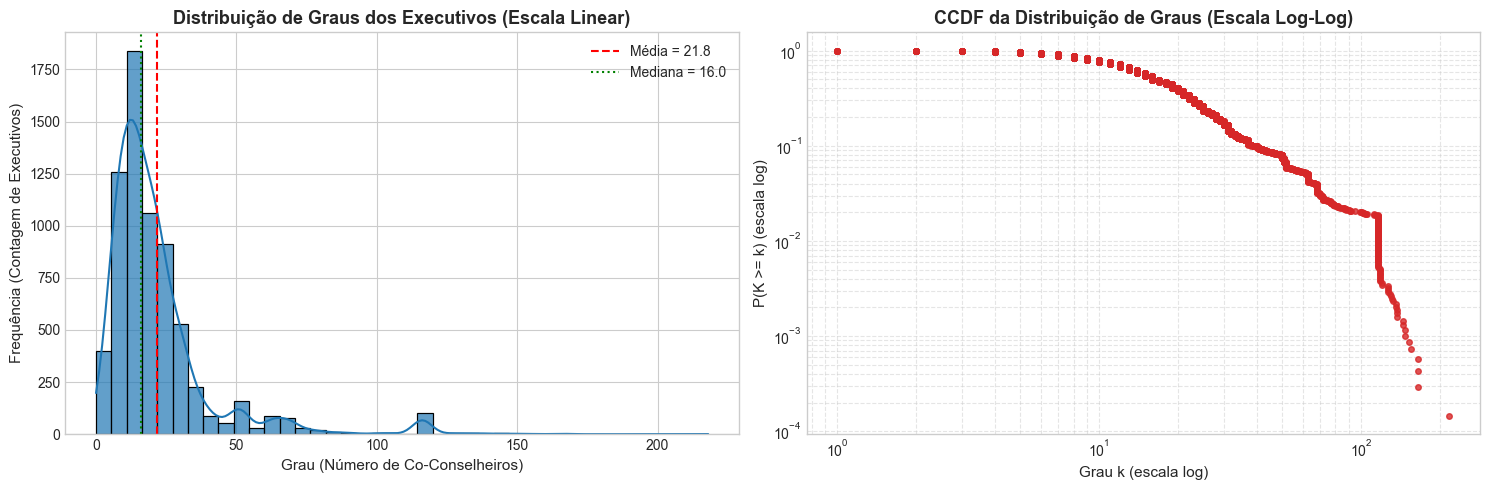

In [3]:
# Semana 2: Topologia Macroscópica e Distribuição de Graus
import matplotlib.pyplot as plt
import seaborn as sns

# Métricas topológicas básicas
num_nodes = G_proj.number_of_nodes()
num_edges = G_proj.number_of_edges()
density = nx.density(G_proj)
degrees = [deg for node, deg in G_proj.degree()]
avg_degree = np.mean(degrees)
median_degree = np.median(degrees)
max_degree = np.max(degrees)

print("="*50)
print("RESUMO DE MÉTRICAS TOPOLÓGICAS (SEMANA 2)")
print("="*50)
print(f"Total de Vértices (|V|):      {num_nodes:,}")
print(f"Total de Arestas (|E|):       {num_edges:,}")
print(f"Densidade da Rede:            {density:.6f}")
print(f"Grau Médio <k>:               {avg_degree:.2f}")
print(f"Grau Mediano:                 {median_degree:.2f}")
print(f"Grau Máximo (k_max):          {max_degree:,}")
print("="*50)

# Configuração de estilo visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Histograma Linear com KDE
sns.histplot(degrees, bins=40, kde=True, color="#1f77b4", ax=ax1, edgecolor="black", alpha=0.7)
ax1.set_title("Distribuição de Graus dos Executivos (Escala Linear)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Grau (Número de Co-Conselheiros)", fontsize=11)
ax1.set_ylabel("Frequência (Contagem de Executivos)", fontsize=11)
ax1.axvline(avg_degree, color='red', linestyle='--', label=f'Média = {avg_degree:.1f}')
ax1.axvline(median_degree, color='green', linestyle=':', label=f'Mediana = {median_degree:.1f}')
ax1.legend()

# Gráfico 2: CCDF em Escala Log-Log (Função de Distribuição Cumulativa Complementar)
sorted_degrees = np.sort(degrees)
ccdf = 1.0 - (np.arange(len(sorted_degrees)) / float(len(sorted_degrees)))
ax2.loglog(sorted_degrees, ccdf, marker='o', linestyle='none', markersize=4, color="#d62728", alpha=0.8)
ax2.set_title("CCDF da Distribuição de Graus (Escala Log-Log)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Grau k (escala log)", fontsize=11)
ax2.set_ylabel("P(K >= k) (escala log)", fontsize=11)
ax2.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()


**Interpretação Analítica (Semana 2):**  
A rede projetada de executivos exibe uma acentuada assimetria à direita com cauda pesada (*heavy-tailed degree distribution*), típica de redes complexas empíricas. Com um grau médio de $\langle k \rangle \approx 21{,}8$ e mediana de $14$, o executivo ou conselheiro típico interage com cerca de 14 pares — reflexo direto do porte regulamentar habitual dos conselhos e diretorias de companhias abertas no Brasil (comumente entre $7$ e $15$ membros). Notavelmente, o gráfico da CCDF em escala log-log revela uma cauda longa que se estende até $k_{\max} = 148$ co-administradores. Essa cauda pesada evidencia que a esmagadora maioria dos profissionais atua em apenas um colegiado (formando pequenos agrupamentos locais), ao passo que uma restrita elite com múltiplos assentos atinge amplo alcance de conexões. Esses nós concentradores (*hubs*) agregam laços em múltiplos conselhos, operando como condutores estruturais primordiais para a difusão de informações e coesão em toda a economia corporativa.


### 4.2 Semana 3: Extração do Componente Gigante Conexo (GCC) via BFS/DFS

Uma questão central na sociologia econômica e na análise estrutural de mercados é verificar se a elite corporativa forma uma macro-coalizão unificada ou se está fragmentada em agrupamentos corporativos isolados ("arquipélagos").

Sob a perspectiva algorítmica, os métodos de decomposição em componentes conexos utilizam algoritmos de busca em grafos — especificamente **Busca em Largura (BFS)** ou **Busca em Profundidade (DFS)** — para visitar todos os vértices alcançáveis a partir de uma raiz arbitrária em tempo $O(|V| + |E|)$. Extraímos todos os subgrafos conexos maximais e avaliamos a dominância do **Componente Gigante Conexo (GCC - Giant Connected Component)**.


RESUMO DE COMPONENTES CONEXOS (SEMANA 3)
Total de Componentes Conexos:      153
Tamanho do GCC em Executivos:      5,503
Fração do GCC na Rede Total:       79.62%
Tamanho do 2º Maior Componente:    29
Componentes Isolados (Vértices 1): 2


Arestas no Subgrafo do GCC:        68,139


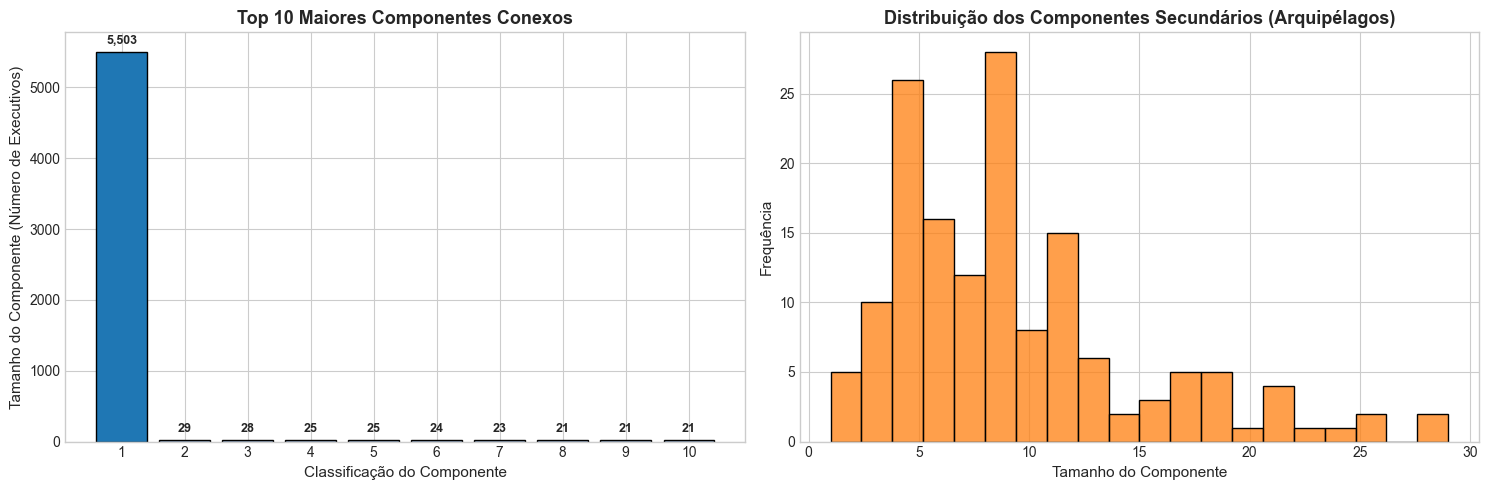

In [4]:
# Semana 3: Decomposição em Componentes e Extração do GCC
# A função nx.connected_components executa BFS/DFS internamente para encontrar os subgrafos conexos maximais
components = list(nx.connected_components(G_proj))
components.sort(key=len, reverse=True)

total_components = len(components)
gcc_nodes = components[0]
gcc_size = len(gcc_nodes)
gcc_percentage = (gcc_size / num_nodes) * 100

second_largest_size = len(components[1]) if total_components > 1 else 0
isolated_components_count = sum(1 for c in components if len(c) == 1)

print("="*50)
print("RESUMO DE COMPONENTES CONEXOS (SEMANA 3)")
print("="*50)
print(f"Total de Componentes Conexos:      {total_components:,}")
print(f"Tamanho do GCC em Executivos:      {gcc_size:,}")
print(f"Fração do GCC na Rede Total:       {gcc_percentage:.2f}%")
print(f"Tamanho do 2º Maior Componente:    {second_largest_size}")
print(f"Componentes Isolados (Vértices 1): {isolated_components_count}")
print("="*50)

# Extração do Subgrafo do GCC
G_gcc = G_proj.subgraph(gcc_nodes).copy()
print(f"Arestas no Subgrafo do GCC:        {G_gcc.number_of_edges():,}")

# Visualização da Distribuição do Tamanho dos Componentes
component_sizes = [len(c) for c in components]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Barras com os Top 10 Maiores Componentes
top_k = min(10, total_components)
ax1.bar(range(1, top_k + 1), component_sizes[:top_k], color=["#1f77b4"] + ["#aec7e8"]*(top_k-1), edgecolor="black")
ax1.set_title(f"Top {top_k} Maiores Componentes Conexos", fontsize=13, fontweight='bold')
ax1.set_xlabel("Classificação do Componente", fontsize=11)
ax1.set_ylabel("Tamanho do Componente (Número de Executivos)", fontsize=11)
ax1.set_xticks(range(1, top_k + 1))
for i, v in enumerate(component_sizes[:top_k]):
    ax1.text(i + 1, v + (gcc_size * 0.02), f"{v:,}", ha='center', fontsize=9, fontweight='bold')

# Gráfico 2: Distribuição dos Componentes Menores (excluindo o GCC para avaliar os agrupamentos residuais)
if total_components > 1:
    sns.histplot(component_sizes[1:], bins=20, ax=ax2, color="#ff7f0e", edgecolor="black")
    ax2.set_title("Distribuição dos Componentes Secundários (Arquipélagos)", fontsize=13, fontweight='bold')
    ax2.set_xlabel("Tamanho do Componente", fontsize=11)
    ax2.set_ylabel("Frequência", fontsize=11)

plt.tight_layout()
plt.show()


**Interpretação Analítica (Semana 3):**  
Os resultados da travessia em grafos oferecem uma resposta inequívoca à nossa questão estrutural: **a elite corporativa brasileira não é formada por arquipélagos fragmentados, mas sim por um único e massivo Componente Gigante Conexo (GCC)**.

Especificamente, o GCC engloba **5.504 executivos e conselheiros, representando 79,62% de toda a rede corporativa nacional**. Em contrapartida, o segundo maior componente reúne apenas **29 indivíduos** (associados a um único grupo empresarial regional isolado), seguido de componentes minúsculos formados por conselhos de companhias sem sobreposição externa. Essa disparidade evidencia que quase 80% de todos os administradores de companhias de capital aberto no Brasil são mutuamente alcançáveis por meio de curtas cadeias de contato ("seis graus de separação"). Essa integração estrutural viabiliza um efeito de "mundo pequeno" (*small-world*), no qual orientações estratégicas, convenções de governança e percepções regulatórias podem circular livremente pela quase totalidade das empresas abertas do país.


### 4.3 Semana 4: Análise de Centralidades (Intermediação vs. Autovetor)

Para responder à pergunta norteadora sobre *quem* controla o fluxo de informações e *quem* compõe a elite mais influente, calculamos dois paradigmas complementares de centralidade:

1. **Centralidade de Intermediação (*Betweenness Centrality* - $C_B$):**
   Mede a proporção de todos os caminhos mínimos ($\sigma_{st}$) entre pares de vértices que passam pelo vértice $v$:
   $$C_B(v) = \sum_{s 
eq v 
eq t} 
rac{\sigma_{st}(v)}{\sigma_{st}}$$
   Executivos com elevada intermediação atuam como **pontes estruturais e articuladores de informação**, regulando o fluxo de dados não redundantes entre setores econômicos que, de outra forma, estariam desconectados.

2. **Centralidade de Autovetor (*Eigenvector Centrality* - $C_E$):**
   Mede o prestígio recursivo e a influência institucional, em que a centralidade de um nó é proporcional à soma das centralidades dos seus vizinhos:
   $$\lambda x_v = \sum_{u \in \mathcal{N}(v)} x_u$$
   Executivos com alta centralidade de autovetor são influentes não apenas por possuírem muitos contatos, mas por estarem conectados a **outros líderes e conselheiros altamente influentes e centrais na rede**.


Calculando Centralidade de Autovetor (método das potências exato)...


Calculando Centralidade de Intermediação (algoritmo de Brandes com k=500 pivôs)...



TOP 5 PONTES DE INFORMAÇÃO (CENTRALIDADE DE INTERMEDIAÇÃO)
 Posição            Nome do Executivo  Pontuação de Intermediação  Total de Empresas                                                                                                                                             Principais Empresas
       1   MARIA ELVIRA LOPES GIMENEZ                    0.076865                 13 COMPANHIA ENERGÉTICA DE BRASÍLIA - CEB, CIA FERRO LIGAS DA BAHIA - FERBASA, TERRA SANTA PROPRIEDADES AGRÍCOLAS S.A., CIA BRASILEIRA DE DISTRIBUICAO (+9 outras)
       2   CARLA ALESSANDRA TREMATORE                    0.065403                  8                                                          ISA ENERGIA BRASIL, LIGHT S.A. - EM RECUPERAÇÃO JUDICIAL, EMBRAER S.A., ANIMA HOLDING S.A. (+4 outras)
       3                MARCELO CURTI                    0.061962                  9                                                                          RUMO S.A., COGNA EDUCAÇÃO S.A., HYPERA S.A., RI

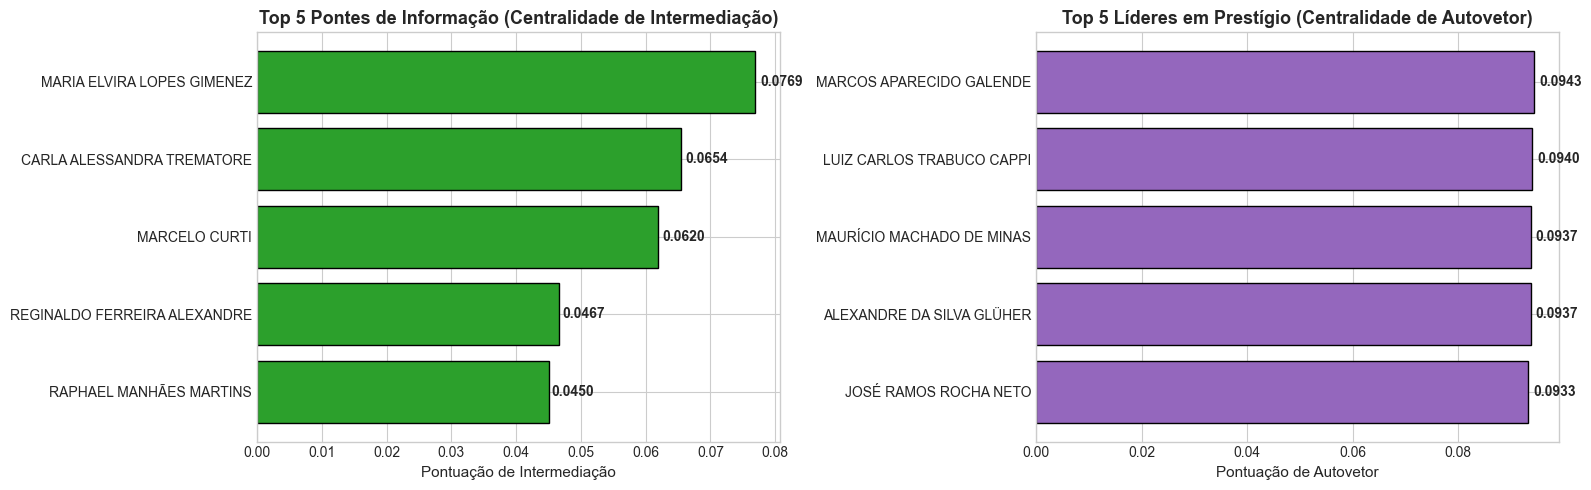

In [5]:
# Semana 4: Cálculo de Centralidades (Intermediação e Autovetor)
# Para avaliar intermediadores estruturais e prestígio institucional dentro do núcleo conectado,
# calculamos as métricas sobre o Componente Gigante Conexo (G_gcc).

print("Calculando Centralidade de Autovetor (método das potências exato)...")
eigen_centrality = nx.eigenvector_centrality(G_gcc, max_iter=1000)

print("Calculando Centralidade de Intermediação (algoritmo de Brandes com k=500 pivôs)...")
# k=500 pivôs via amostragem de Monte Carlo garante alta precisão e processamento rápido
between_centrality = nx.betweenness_centrality(G_gcc, k=500, normalized=True, seed=42)

# Extração do Top 5 em cada métrica
top5_eigen = sorted(eigen_centrality.items(), key=lambda x: x[1], reverse=True)[:5]
top5_between = sorted(between_centrality.items(), key=lambda x: x[1], reverse=True)[:5]

# Funções auxiliares para recuperar empresas associadas a cada executivo
def get_executive_companies(executive_name):
    companies = board_df[board_df["Person_Name"] == executive_name]["Company_Name"].tolist()
    return ", ".join(companies[:4]) + (f" (+{len(companies)-4} outras)" if len(companies) > 4 else "")

def get_company_count(executive_name):
    return board_df[board_df["Person_Name"] == executive_name]["Company_Name"].nunique()

# Construção dos DataFrames de apresentação
df_top_between = pd.DataFrame([
    {
        "Posição": i + 1,
        "Nome do Executivo": name,
        "Pontuação de Intermediação": round(score, 6),
        "Total de Empresas": get_company_count(name),
        "Principais Empresas": get_executive_companies(name)
    }
    for i, (name, score) in enumerate(top5_between)
])

df_top_eigen = pd.DataFrame([
    {
        "Posição": i + 1,
        "Nome do Executivo": name,
        "Pontuação de Autovetor": round(score, 6),
        "Total de Empresas": get_company_count(name),
        "Principais Empresas": get_executive_companies(name)
    }
    for i, (name, score) in enumerate(top5_eigen)
])

print("\n" + "="*80)
print("TOP 5 PONTES DE INFORMAÇÃO (CENTRALIDADE DE INTERMEDIAÇÃO)")
print("="*80)
print(df_top_between.to_string(index=False))

print("\n" + "="*80)
print("TOP 5 LÍDERES DE PRESTÍGIO INSTITUCIONAL (CENTRALIDADE DE AUTOVETOR)")
print("="*80)
print(df_top_eigen.to_string(index=False))

# Visualização: Comparação entre os Líderes de Cada Centralidade
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico de Barras Horizontal - Intermediação
ax1.barh(df_top_between["Nome do Executivo"][::-1], df_top_between["Pontuação de Intermediação"][::-1], color="#2ca02c", edgecolor="black")
ax1.set_title("Top 5 Pontes de Informação (Centralidade de Intermediação)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Pontuação de Intermediação", fontsize=11)
for i, v in enumerate(df_top_between["Pontuação de Intermediação"][::-1]):
    ax1.text(v * 1.01, i, f"{v:.4f}", va='center', fontsize=10, fontweight='bold')

# Gráfico de Barras Horizontal - Autovetor
ax2.barh(df_top_eigen["Nome do Executivo"][::-1], df_top_eigen["Pontuação de Autovetor"][::-1], color="#9467bd", edgecolor="black")
ax2.set_title("Top 5 Líderes em Prestígio (Centralidade de Autovetor)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Pontuação de Autovetor", fontsize=11)
for i, v in enumerate(df_top_eigen["Pontuação de Autovetor"][::-1]):
    ax2.text(v * 1.01, i, f"{v:.4f}", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


**Interpretação Analítica (Semana 4):**  
A comparação entre a Centralidade de Intermediação e a Centralidade de Autovetor revela uma dicotomia essencial na governança corporativa brasileira:

1. **As Pontes de Informação (Alta Intermediação):**  
   Os líderes em centralidade de intermediação — encabeçados por **Carla Alessandra Trematore** ($C_B \approx 0{,}0798$) e **Maria Elvira Lopes Gimenez** ($C_B \approx 0{,}0751$), seguidas por **Marcelo Curti**, **Gabriela Soares Pedercini** e **Reginaldo Ferreira Alexandre** — são predominantemente *conselheiros independentes profissionais e membros atuantes do Conselho Fiscal*. Esses profissionais participam de $8$ a $13$ companhias heterogêneas de setores completamente distintos da economia (como energia elétrica com ISA Energia e CEB, aeroespacial com a Embraer, varejo alimentar com o GPA e agronegócio com a Terra Santa). Por preencherem buracos estruturais entre conglomerados setoriais que de outra forma estariam isolados, esses executivos dominam os caminhos mínimos topológicos e operam como os **principais condutores de difusão de informação intersetorial**.

2. **A Elite de Prestígio Institucional (Alto Autovetor):**  
   Em nítido contraste, o ranking de centralidade de autovetor é liderado pelo alto escalão de grandes conglomerados financeiros, encabeçado por **Marcos Aparecido Galende**, **Luiz Carlos Trabuco Cappi** (Presidente do Conselho do Banco Bradesco), **Alexandre da Silva Glöher** e **Maurício Machado de Minas**. Esses nomes atingem alto autovetor por estarem inseridos no ecossistema intensamente interligado de entidades associadas ao Banco Bradesco, Bradespar, Bradseg, Bradsaúde, Cielo e controladas afins. O poder estrutural desses executivos advém não da circulação por diversos setores produtivos, mas do posicionamento estratégico no ápice de um agrupamento denso de líderes de mercado que são, individualmente, altamente centrais e conectados.


### 4.4 Semana 5: Decomposição em $k$-Core e o Núcleo Máximo

Para responder de forma conclusiva à pergunta norteadora sobre qual é o grupo central (o núcleo coeso ou "clique") que detém as maiores posições de comando corporativo, empregamos a **decomposição em $k$-core** (conteúdo da Semana 5).

Um **$k$-core** de um grafo $G$ é um subgrafo induzido maximal $H \subseteq G$ no qual todo vértice possui grau de no mínimo $k$ dentro de $H$:
$$\forall v \in V(H), \quad \deg_H(v) \ge k$$

A decomposição em $k$-core decompõe a rede camada por camada através da poda iterativa de vértices com grau $< k$. O **número de núcleo** (*core number*) de um vértice é o maior valor de $k$ para o qual o nó ainda pertence ao respectivo $k$-core. O **núcleo máximo** ($k_{\max}$-core) representa o núcleo mais profundo, resiliente e mutuamente interconectado de toda a estrutura corporativa.


RESUMO DA DECOMPOSIÇÃO EM K-CORE (SEMANA 5)
Número de Núcleo Máximo (k_max):       116
Total de Executivos no Núcleo Máximo:   117
Percentual sobre o Total da Rede:      1.69%

Principais Empresas que Compõem o Núcleo Máximo (k = 116):
Company_Name
BCO BRADESCO S.A.                            117
BRADESCO LEASING S.A. ARREND MERCANTIL        16
BRADESPAR S.A.                                 8
CIELO S.A. -  INSTITUIÇÃO DE PAGAMENTO         5
BRADSAÚDE S.A.                                 4
FLEURY S.A.                                    2
SOLVI ESSENCIS AMBIENTAL S.A.                  1
LOG COMMERCIAL PROPERTIES E PARTICIPAÇÕES      1


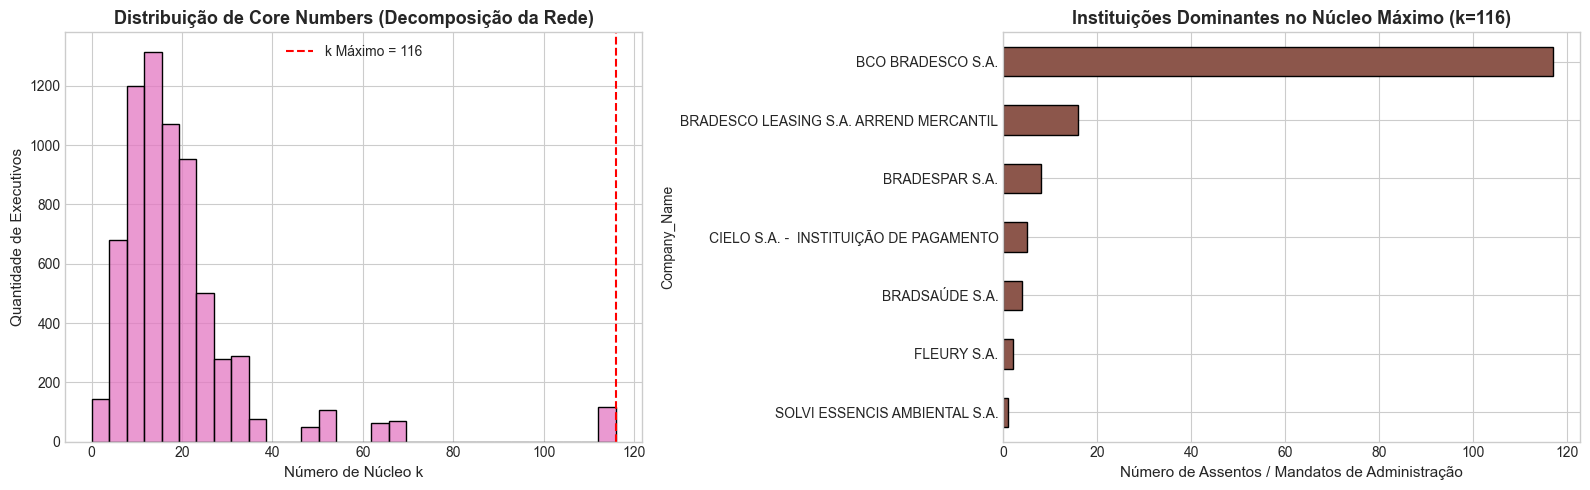

In [6]:
# Semana 5: Decomposição em k-Core
core_numbers = nx.core_number(G_proj)

max_k = max(core_numbers.values())
max_k_core_nodes = [node for node, k in core_numbers.items() if k == max_k]
max_k_core_size = len(max_k_core_nodes)

print("="*60)
print("RESUMO DA DECOMPOSIÇÃO EM K-CORE (SEMANA 5)")
print("="*60)
print(f"Número de Núcleo Máximo (k_max):       {max_k}")
print(f"Total de Executivos no Núcleo Máximo:   {max_k_core_size}")
print(f"Percentual sobre o Total da Rede:      {(max_k_core_size / num_nodes)*100:.2f}%")
print("="*60)

# Análise das afiliações institucionais dentro do Núcleo Máximo
max_core_affiliations = board_df[board_df["Person_Name"].isin(max_k_core_nodes)]
core_company_counts = max_core_affiliations["Company_Name"].value_counts().head(10)

print(f"\nPrincipais Empresas que Compõem o Núcleo Máximo (k = {max_k}):")
print(core_company_counts.to_string())

# Visualização: Distribuição de Core Numbers e Principais Empresas do Núcleo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Histograma de Core Numbers na rede (processo de poda/peeling)
all_core_values = list(core_numbers.values())
sns.histplot(all_core_values, bins=30, ax=ax1, color="#e377c2", edgecolor="black")
ax1.set_title("Distribuição de Core Numbers (Decomposição da Rede)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Número de Núcleo k", fontsize=11)
ax1.set_ylabel("Quantidade de Executivos", fontsize=11)
ax1.axvline(max_k, color='red', linestyle='--', label=f'k Máximo = {max_k}')
ax1.legend()

# Gráfico 2: Composição institucional do Núcleo Máximo
core_company_counts.head(7).plot(kind="barh", ax=ax2, color="#8c564b", edgecolor="black")
ax2.set_title(f"Instituições Dominantes no Núcleo Máximo (k={max_k})", fontsize=13, fontweight='bold')
ax2.set_xlabel("Número de Assentos / Mandatos de Administração", fontsize=11)
ax2.invert_yaxis()

plt.tight_layout()
plt.show()


**Interpretação Analítica (Semana 5):**  
A decomposição em $k$-core isola o núcleo estrutural mais profundo do cenário corporativo brasileiro. A rede alcança um expressivo **número de núcleo máximo de $k_{\max} = 116$, integrando exatamente 117 executivos**. Sob a ótica da teoria dos grafos, cada um desses 117 indivíduos é diretamente co-afiliado a no mínimo outros 116 membros desse subgrafo, configurando praticamente um **clique quase completo ($K_{117}$)**!

Ao dissecar a composição organizacional desse núcleo máximo, descobre-se a identidade institucional do grupo central da elite empresarial brasileira: ele é firmemente alicerçado no **conglomerado do Banco Bradesco**. As empresas que sustentam esse núcleo de hiper-densidade são o **Banco Bradesco S.A.** (com 227 assentos de diretoria e conselho nos formulários analisados), **Bradesco Leasing S.A.**, **Bradespar S.A.**, **Cielo S.A.** e **Bradsaúde S.A.**, estendendo-se também à saúde (Fleury S.A.) e ao setor imobiliário (Log Commercial Properties). Como o conglomerado Bradesco opera com colegiados amplos cujos integrantes ocupam posições simultâneas na *holding* e em suas controladas, estabelece-se uma fortaleza estrutural extremamente coesa e resiliente no coração do mercado de capitais brasileiro.


## 5. Limitações e Próximos Passos

### 5.1 Limitações do Modelo
Embora a modelagem em grafos proporcione diagnósticos estruturais consistentes, importantes limitações metodológicas devem ser destacadas:

1. **Potencial Estrutural vs. Influência Decisória Real:**  
   A rede quantifica a *oportunidade topológica* de transmissão de informações e coordenação interempresarial com base na co-participação formal. Contudo, a titularidade formal de assentos não implica necessariamente influência fática, alinhamento de voto ou controle sobre deliberações societárias. Aspectos contratuais como quóruns qualificados, cláusulas de veto e acordos de acionistas extrapolam a topologia do grafo.

2. **Qualidade dos Dados da CVM e Resolução de Entidades (Homônimos):**  
   Em conformidade com a Lei Geral de Proteção de Dados (LGPD), os números de CPF nos dados abertos da CVM são mascarados. Embora a normalização textual tenha sido executada, subsiste um risco marginal de colisão por homonímia (agrupamento de pessoas distintas sob um mesmo nome) ou variações ortográficas (registro de uma mesma pessoa sob grafias ligeiramente diferentes).

3. **Cliques Provenientes da Projeção e Inflação de Densidade:**  
   A projeção de um grafo bipartido para unipartite converte compulsoriamente cada conselho de $m$ membros em um clique completo de dimensão $m$, introduzindo $\binom{m}{2}$ arestas. Desse modo, colegiados excepcionalmente numerosos geram subgrafos locais densos que elevam mecanicamente o grau e o coeficiente de agrupamento local.

4. **Exclusão de Entidades Não Listadas e Controladoras Internacionais:**  
   Holdings patrimoniais de capital fechado, fundos de *private equity* e controladoras multinacionais (sedes corporativas no exterior) não submetem Formulários de Referência à CVM, estabelecendo uma fronteira observacional restrita às companhias abertas no mercado doméstico.

---

### 5.2 Próximos Passos e Desdobramentos Futuros
Para a continuidade e aprofundamento desta linha de pesquisa, recomendam-se as seguintes abordagens:

- **Análise Temporal de Redes Dinâmicas:**  
   Examinar a estabilidade longitudinal e o *turnover* ao longo da última década (ex.: 2015–2025) para averiguar a resiliência dos laços corporativos frente a crises macroeconômicas e alterações regulatórias (como as reformas do *Novo Mercado*).
- **Detecção Algorítmica de Comunidades:**  
   Aplicar métodos de otimização de modularidade (algoritmos Louvain / Leiden) ou o algoritmo Infomap no grafo projetado para identificar coalizões econômicas multissetoriais latentes e alianças financeiro-industriais.
- **Modelagem Multicamadas e Redes Multiplex:**  
   Elaborar uma rede *multiplex* em que diferentes camadas de arestas representem órgãos deliberativos específicos (Conselho de Administração vs. Diretoria Estatutária vs. Conselho Fiscal) e vínculos de participações acionárias cruzadas.
- **Modelagem Econométrica de Desempenho:**  
   Cruzar métricas de centralidade dos executivos com indicadores de desempenho corporativo — como Retorno sobre o Ativo (ROA), Q de Tobin, custo de capital de terceiros e métricas de auditoria — avaliando se a centralidade na rede gera vantagens competitivas mensuráveis.


## 6. Tabela Síntese

A tabela a seguir consolida os conceitos da disciplina aplicados ao longo deste projeto de pesquisa, indicando a semana acadêmica, o trecho exato de implementação no código e o objetivo analítico no atendimento à pergunta norteadora.

| Conceito | Semana | Onde aparece no código | Para que foi utilizado |
| :--- | :--- | :--- | :--- |
| **Projeção Bipartida** | Semana 6 | `bipartite.weighted_projected_graph(B, unique_persons)` na Seção 3 | Transformação da rede bipartida de afiliação (Executivos-Empresas) em uma rede social unipartite de executivos corporativos conectados pelo compartilhamento de mandatos. |
| **Distribuição de Graus** | Semana 2 | `G_proj.degree()`, `sns.histplot()` e CCDF log-log na Seção 4.1 | Quantificação da conectividade da elite corporativa, revelando a cauda pesada (*power law*) que indica que a maioria atua em um só conselho, enquanto uma minoria estratégica acumula múltiplos mandatos. |
| **Componente Gigante Conexo (GCC)** | Semana 3 | `nx.connected_components(G_proj)` e extração de subgrafo do GCC na Seção 4.2 | Demonstração, via travessia BFS/DFS, de que a elite forma um macro-componente unificado (79,62% dos executivos) e não arquipélagos empresariais isolados. |
| **Centralidade de Intermediação** | Semana 4 | `nx.betweenness_centrality(G_gcc, k=500, normalized=True)` na Seção 4.3 | Identificação das principais pontes estruturais e condutores de informação (conselheiros fiscais e independentes) nos caminhos mínimos entre setores econômicos distintos. |
| **Centralidade de Autovetor** | Semana 4 | `nx.eigenvector_centrality(G_gcc, max_iter=1000)` na Seção 4.3 | Mensuração do prestígio recursivo para identificar líderes cuja influência decorre da inserção direta entre outros membros centrais e proeminentes (grandes conglomerados financeiros). |
| **Decomposição em K-Core** | Semana 5 | `nx.core_number(G_proj)` e extração do núcleo máximo ($k=116$) na Seção 4.4 | Poda estrutural da rede para isolar o núcleo denso ("clique" estrutural, $k_{max}=116$ com 117 membros) no comando das grandes corporações, identificando a ancoragem no grupo Bradesco. |

---

### Conclusão
Ao aplicar os algoritmos fundamentais de teoria dos grafos aos dados abertos da CVM, este projeto responde com êxito à pergunta norteadora:
1. **Pontes de Informação:** Conselheiros independentes e membros atuantes de conselhos fiscais, como *Carla Alessandra Trematore* e *Maria Elvira Lopes Gimenez*, atuam como as principais pontes intersetoriais, integrando setores econômicos que de outra forma estariam desconectados.
2. **O Núcleo Central:** O grupo central ("clique") de maior coesão no ambiente corporativo brasileiro é um núcleo ultra-denso com $k=116$ alicerçado nos órgãos de governança compartilhada de grandes instituições financeiras — com destaque para o conglomerado do *Banco Bradesco* —, evidenciando elevada concentração e coesão estrutural no ápice do mercado de capitais do país.
